<a href="https://colab.research.google.com/github/arambhaghimirecs24-stack/BIS/blob/main/1BF24CS062_ant_colony_optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Best route:
J -> E -> I -> H -> L -> D -> G -> K -> B -> F -> A -> C -> J
Shortest distance: 48.22


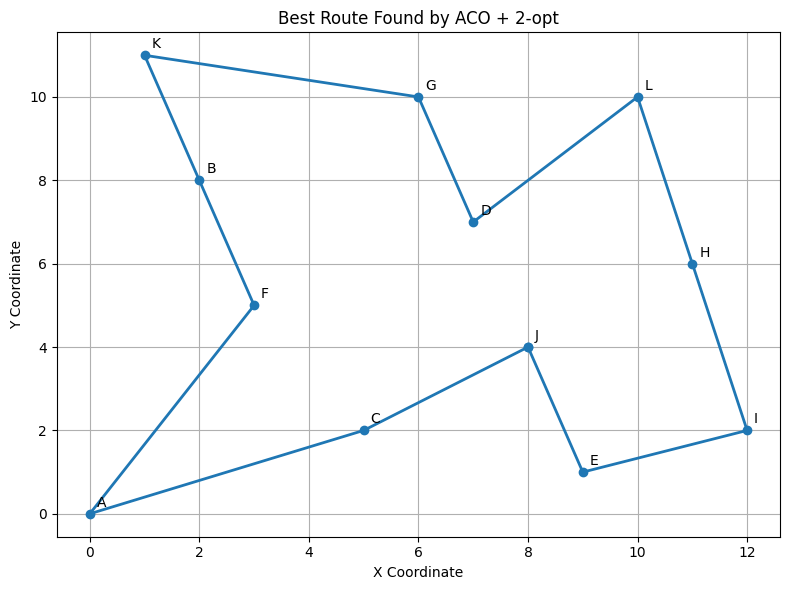

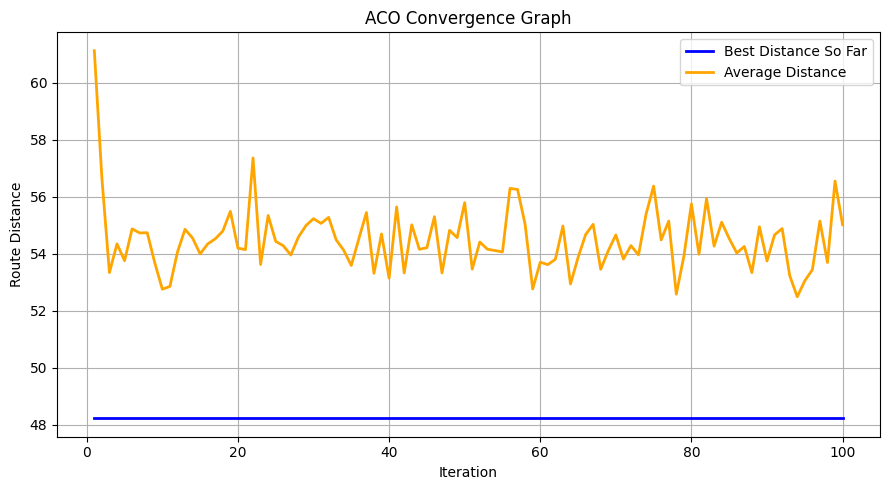

In [4]:

import numpy as np
import random
import matplotlib.pyplot as plt

random.seed(10)
np.random.seed(10)

# City coordinates
cities = np.array([
    [0, 0], [2, 8], [5, 2], [7, 7],
    [9, 1], [3, 5], [6, 10], [11, 6],
    [12, 2], [8, 4], [1, 11], [10, 10]
], dtype=float)

city_names = [chr(65 + i) for i in range(len(cities))]
n = len(cities)

# Calculate distances between cities
dist = np.linalg.norm(
    cities[:, None, :] - cities[None, :, :],
    axis=2
)

# ACO parameters
ants = 20
iterations = 100
alpha = 1.0
beta = 3.0
rho = 0.3
Q = 100.0

pheromone = np.ones((n, n))
visibility = 1 / (dist + np.eye(n))
np.fill_diagonal(visibility, 0)


def route_length(route):
    return sum(
        dist[route[i], route[(i + 1) % len(route)]]
        for i in range(len(route))
    )


def two_opt(route):
    route = route.copy()
    improved = True

    while improved:
        improved = False

        for i in range(1, n - 1):
            for j in range(i + 2, n + 1):
                candidate = (
                    route[:i]
                    + route[i:j][::-1]
                    + route[j:]
                )

                if route_length(candidate) < route_length(route):
                    route = candidate
                    improved = True

    return route


# Best solution tracking
best_route = None
best_length = float("inf")

best_history = []
average_history = []
iteration_best_history = []

# Main ACO loop
for iteration in range(iterations):
    routes = []
    current_lengths = []

    for ant in range(ants):

        # Select starting city
        route = [random.randrange(n)]
        unvisited = set(range(n)) - set(route)

        # Construct a complete route
        while unvisited:
            current = route[-1]
            choices = list(unvisited)

            weights = [
                pheromone[current, city] ** alpha
                * visibility[current, city] ** beta
                for city in choices
            ]

            next_city = random.choices(
                choices,
                weights=weights,
                k=1
            )[0]

            route.append(next_city)
            unvisited.remove(next_city)

        # Apply 2-opt to some ants
        if ant % 3 == 0:
            route = two_opt(route)

        length = route_length(route)

        routes.append((route, length))
        current_lengths.append(length)

        # Track best route found so far
        if length < best_length:
            best_length = length
            best_route = route.copy()

    # Record this iteration's best and average distances
    iteration_best_history.append(min(current_lengths))
    best_history.append(best_length)
    average_history.append(np.mean(current_lengths))

    # Evaporate pheromones
    pheromone *= (1 - rho)

    # Deposit pheromones on routes
    for route, length in routes:
        deposit = Q / length

        for i in range(n):
            a = route[i]
            b = route[(i + 1) % n]

            pheromone[a, b] += deposit
            pheromone[b, a] += deposit


# Print final result
closed_route = best_route + [best_route[0]]

print("Best route:")
print(" -> ".join(city_names[i] for i in closed_route))
print("Shortest distance:", round(best_length, 2))


# GRAPH 1: Best route
plt.figure(figsize=(8, 6))

route_points = cities[closed_route]

plt.plot(
    route_points[:, 0],
    route_points[:, 1],
    marker="o",
    linewidth=2
)

for i, (x, y) in enumerate(cities):
    plt.annotate(
        city_names[i],
        (x, y),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.title("Best Route Found by ACO + 2-opt")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.grid(True)
plt.tight_layout()
plt.show()


# GRAPH 2: Convergence graph
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, iterations + 1),
    best_history,
    label="Best Distance So Far",
    color="blue",
    linewidth=2
)

plt.plot(
    range(1, iterations + 1),
    average_history,
    label="Average Distance",
    color="orange",
    linewidth=2
)

plt.title("ACO Convergence Graph")
plt.xlabel("Iteration")
plt.ylabel("Route Distance")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
